<a href="https://colab.research.google.com/github/leonardo2004/Calculo-Numerico/blob/main/Atividade%2003/Atividade%2003_CalcNumerico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Nomes: Lucas Daniel Andrade do Prado - 168970
        LEONARDO TOMASELA LEAL - 170291

Newton

In [ ]:
import math
import pandas as pd


# 1. Função Newton ajustada conforme as especificações exigidas
def newton(f, df, x0, tol=1e-6, max_iter=100, deriv_tol=1e-14):
    """Resolve f(x) = 0 pelo Método de Newton.

    Retorna:
    - x: aproximação final da raiz
    - historico: lista de dicionários com os passos da iteração
    - estado: indicação de convergência ou falha
    """
    x = float(x0)
    historico = []

    for k in range(max_iter):
        fx = f(x)
        dfx = df(x)

        historico.append({"k": k, "x": x, "f(x)": fx, "f'(x)": dfx})

        # Critério de parada pelo resíduo no ponto atual |f(x)| < tol
        if abs(fx) < tol:
            return x, historico, "convergiu pelo resíduo (|f(x)| < tol)"

        # Verificação de derivada nula ou muito próxima de zero
        if abs(dfx) <= deriv_tol:
            return x, historico, "parou: derivada nula ou muito próxima de zero"

        # Atualização pelo método de Newton
        x_novo = x - fx / dfx

        # Critério de parada pela diferença de aproximações sucessivas |x_{k+1} - x_k| < tol
        if abs(x_novo - x) < tol:
            x = x_novo
            fx_novo = f(x)
            dfx_novo = df(x)
            historico.append(
                {"k": k + 1, "x": x, "f(x)": fx_novo, "f'(x)": dfx_novo}
            )
            return x, historico, "convergiu pela diferença de passo (|x_{k+1} - x_k| < tol)"

        x = x_novo

    return x, historico, "parou: atingiu o número máximo de iterações"


# 2. Definição das funções e derivadas apresentadas na imagem
funcoes_teste = [
    {
        "nome": "f1(x) = x^2 - 2",
        "f": lambda x: x**2 - 2,
        "df": lambda x: 2 * x,
        "x0": 1.5,
    },
    {
        "nome": "f2(x) = x^3 - x - 2",
        "f": lambda x: x**3 - x - 2,
        "df": lambda x: 3 * x**2 - 1,
        "x0": 1.5,
    },
    {
        "nome": "f3(x) = e^(-x) - x",
        "f": lambda x: math.exp(-x) - x,
        "df": lambda x: -math.exp(-x) - 1,
        "x0": 0.5,
    },
    {
        "nome": "f4(x) = x^3 - 2x + 2",
        "f": lambda x: x**3 - 2 * x + 2,
        "df": lambda x: 3 * x**2 - 2,
        "x0": -2.0,
    },
]

# 3. Execução do método para cada função da tabela
for item in funcoes_teste:
    raiz, hist, estado = newton(
        item["f"], item["df"], x0=item["x0"], tol=1e-6, max_iter=100
    )

    print("=" * 60)
    print(f"Função: {item['nome']}")
    print(f"Ponto Inicial (x0): {item['x0']}")
    print(f"Raiz aproximada: {raiz:.8f}")
    print(f"Resíduo |f(raiz)|: {abs(item['f'](raiz)):.2e}")
    print(f"Iterações realizadas: {len(hist) - 1}")
    print(f"Estado de convergência: {estado}")
    print("\nTabela de Iterações:")
    df_hist = pd.DataFrame(hist)
    print(df_hist.to_string(index=False))
    print("\n")

Função: f1(x) = x^2 - 2
Ponto Inicial (x0): 1.5
Raiz aproximada: 1.41421356
Resíduo |f(raiz)|: 4.51e-12
Iterações realizadas: 3
Estado de convergência: convergiu pelo resíduo (|f(x)| < tol)

Tabela de Iterações:
 k        x         f(x)    f'(x)
 0 1.500000 2.500000e-01 3.000000
 1 1.416667 6.944444e-03 2.833333
 2 1.414216 6.007305e-06 2.828431
 3 1.414214 4.510614e-12 2.828427


Função: f2(x) = x^3 - x - 2
Ponto Inicial (x0): 1.5
Raiz aproximada: 1.52137981
Resíduo |f(raiz)|: 5.89e-07
Iterações realizadas: 2
Estado de convergência: convergiu pelo resíduo (|f(x)| < tol)

Tabela de Iterações:
 k        x          f(x)   f'(x)
 0 1.500000 -1.250000e-01 5.75000
 1 1.521739  2.136928e-03 5.94707
 2 1.521380  5.893874e-07 5.94379


Função: f3(x) = e^(-x) - x
Ponto Inicial (x0): 0.5
Raiz aproximada: 0.56714317
Resíduo |f(raiz)|: 1.96e-07
Iterações realizadas: 2
Estado de convergência: convergiu pelo resíduo (|f(x)| < tol)

Tabela de Iterações:
 k        x         f(x)     f'(x)
 0 0.500000 

Secantes:

In [ ]:
import math
import pandas as pd


# 1. Função Secante ajustada conforme as especificações da Parte 1
def secante(f, x0, x1, tol=1e-6, max_iter=100, denom_tol=1e-14):
    """Resolve f(x) = 0 pelo Método da Secante.

    Retorna:
    - x: aproximação final da raiz
    - historico: lista com o histórico de iterações
    - estado: indicação de convergência ou falha
    """
    x_anterior = float(x0)
    x_atual = float(x1)
    historico = []

    for k in range(max_iter):
        f_anterior = f(x_anterior)
        f_atual = f(x_atual)

        historico.append({"k": k, "x": x_atual, "f(x)": f_atual})

        # Critério de parada pelo resíduo |f(x)| < tol
        if abs(f_atual) < tol:
            return x_atual, historico, "convergiu pelo resíduo (|f(x)| < tol)"

        denominador = f_atual - f_anterior

        # Verificação do denominador muito próximo de zero
        if abs(denominador) <= denom_tol:
            return (
                x_atual,
                historico,
                "parou: denominador nulo ou muito próximo de zero",
            )

        # Atualização pela fórmula da Secante
        x_novo = x_atual - f_atual * (x_atual - x_anterior) / denominador

        # Critério de parada pela diferença de aproximações sucessivas |x_{k+1} - x_k| < tol
        if abs(x_novo - x_atual) < tol:
            f_novo = f(x_novo)
            historico.append({"k": k + 1, "x": x_novo, "f(x)": f_novo})
            return (
                x_novo,
                historico,
                "convergiu pela diferença de passo (|x_{k+1} - x_k| < tol)",
            )

        x_anterior, x_atual = x_atual, x_novo

    return x_atual, historico, "parou: atingiu o número máximo de iterações"


# 2. Definição das funções e seus pares de pontos iniciais (x0, x1)
funcoes_teste_secante = [
    {
        "nome": "f1(x) = x^2 - 2",
        "f": lambda x: x**2 - 2,
        "x0": 1.0,
        "x1": 2.0,
    },
    {
        "nome": "f2(x) = x^3 - x - 2",
        "f": lambda x: x**3 - x - 2,
        "x0": 1.0,
        "x1": 2.0,
    },
    {
        "nome": "f3(x) = e^(-x) - x",
        "f": lambda x: math.exp(-x) - x,
        "x0": 0.0,
        "x1": 1.0,
    },
    {
        "nome": "f4(x) = x^3 - 2x + 2",
        "f": lambda x: x**3 - 2 * x + 2,
        "x0": -2.0,
        "x1": -1.0,
    },
]

# 3. Execução do método para cada função
for item in funcoes_teste_secante:
    raiz, hist, estado = secante(
        item["f"], item["x0"], item["x1"], tol=1e-6, max_iter=100
    )

    print("=" * 60)
    print(f"Função: {item['nome']}")
    print(f"Ponto Inicial (x0, x1): ({item['x0']}, {item['x1']})")
    print(f"Raiz aproximada: {raiz:.8f}")
    print(f"Resíduo |f(raiz)|: {abs(item['f'](raiz)):.2e}")
    print(f"Iterações realizadas: {len(hist) - 1}")
    print(f"Estado de convergência: {estado}")
    print("\nTabela de Iterações:")
    df_hist = pd.DataFrame(hist)
    print(df_hist.to_string(index=False))
    print("\n")

Função: f1(x) = x^2 - 2
Ponto Inicial (x0, x1): (1.0, 2.0)
Raiz aproximada: 1.41421356
Resíduo |f(raiz)|: 8.93e-10
Iterações realizadas: 5
Estado de convergência: convergiu pelo resíduo (|f(x)| < tol)

Tabela de Iterações:
 k        x          f(x)
 0 2.000000  2.000000e+00
 1 1.333333 -2.222222e-01
 2 1.400000 -4.000000e-02
 3 1.414634  1.189768e-03
 4 1.414211 -6.007287e-06
 5 1.414214 -8.931456e-10


Função: f2(x) = x^3 - x - 2
Ponto Inicial (x0, x1): (1.0, 2.0)
Raiz aproximada: 1.52137971
Resíduo |f(raiz)|: 7.02e-09
Iterações realizadas: 6
Estado de convergência: convergiu pelo resíduo (|f(x)| < tol)

Tabela de Iterações:
 k        x          f(x)
 0 2.000000  4.000000e+00
 1 1.333333 -9.629630e-01
 2 1.462687 -3.333389e-01
 3 1.531169  5.862642e-02
 4 1.520926 -2.693300e-03
 5 1.521376 -2.015019e-05
 6 1.521380  7.015478e-09


Função: f3(x) = e^(-x) - x
Ponto Inicial (x0, x1): (0.0, 1.0)
Raiz aproximada: 0.56714331
Resíduo |f(raiz)|: 2.54e-08
Iterações realizadas: 4
Estado de conv

Bisseção:

In [ ]:
import math
import numpy as np
import pandas as pd


# 1. Função Bisseção adaptada para retornar mensagens de retorno sem interromper a execução com raise
def bissecao(f, a, b, tol=1e-6, max_iter=100):
    """Resolve f(x) = 0 pelo Método da Bisseção.

    Retorna:
    - x: aproximação final da raiz
    - historico: lista de dicionários com os passos da iteração
    - estado: indicação de convergência ou falha
    """
    a = float(a)
    b = float(b)

    if a >= b:
        return None, [], "erro: é necessário fornecer a < b"

    fa, fb = f(a), f(b)

    if not np.isfinite([fa, fb]).all():
        return None, [], "erro: a função não é finita nas extremidades"

    # Verificação da condição f(a)*f(b) > 0 exigida no enunciado
    if fa * fb > 0:
        return (
            None,
            [],
            "falha: f(a)*f(b) > 0 (não há garantia de mudança de sinal)",
        )

    if fa == 0:
        return a, [{"k": 0, "a": a, "b": b, "m": a, "f(m)": 0.0}], "a é raiz exata"
    if fb == 0:
        return b, [{"k": 0, "a": a, "b": b, "m": b, "f(m)": 0.0}], "b é raiz exata"

    historico = []

    for k in range(1, max_iter + 1):
        m = a + (b - a) / 2.0
        fm = f(m)
        erro = (b - a) / 2.0

        historico.append(
            {
                "k": k,
                "a": a,
                "b": b,
                "m": m,
                "f(a)": fa,
                "f(m)": fm,
                "f(b)": fb,
                "erro": erro,
            }
        )

        # Critérios de parada: raiz exata ou erro/resíduo menor que a tolerância
        if fm == 0 or erro < tol or abs(fm) < tol:
            if fm == 0:
                motivo = "convergiu: raiz exata"
            elif erro < tol:
                motivo = f"convergiu pelo erro do intervalo (erro < {tol})"
            else:
                motivo = f"convergiu pelo resíduo (|f(m)| < {tol})"
            return m, historico, motivo

        if fa * fm < 0:
            b, fb = m, fm
        else:
            a, fa = m, fm

    return m, historico, "parou: atingiu o número máximo de iterações"


# 2. Definição das funções e seus respetivos intervalos [a, b]
funcoes_teste_bissecao = [
    {
        "nome": "f1(x) = x^2 - 2",
        "f": lambda x: x**2 - 2,
        "a": 1.0,
        "b": 2.0,
    },
    {
        "nome": "f2(x) = x^3 - x - 2",
        "f": lambda x: x**3 - x - 2,
        "a": 1.0,
        "b": 2.0,
    },
    {
        "nome": "f3(x) = e^(-x) - x",
        "f": lambda x: math.exp(-x) - x,
        "a": 0.0,
        "b": 1.0,
    },
    {
        "nome": "f4(x) = x^3 - 2x + 2",
        "f": lambda x: x**3 - 2 * x + 2,
        "a": -2.0,
        "b": -1.0,
    },
]

# 3. Execução do método para cada função
for item in funcoes_teste_bissecao:
    raiz, hist, estado = bissecao(
        item["f"], item["a"], item["b"], tol=1e-6, max_iter=100
    )

    print("=" * 60)
    print(f"Função: {item['nome']}")
    print(f"Intervalo inicial [a, b]: [{item['a']}, {item['b']}]")
    if raiz is not None:
        print(f"Raiz aproximada: {raiz:.8f}")
        print(f"Resíduo |f(raiz)|: {abs(item['f'](raiz)):.2e}")
        print(f"Iterações realizadas: {len(hist)}")
    print(f"Estado de convergência: {estado}")
    if hist:
        print("\nTabela de Iterações:")
        df_hist = pd.DataFrame(hist)
        print(df_hist.to_string(index=False))
    print("\n")

Função: f1(x) = x^2 - 2
Intervalo inicial [a, b]: [1.0, 2.0]
Raiz aproximada: 1.41421413
Resíduo |f(raiz)|: 1.62e-06
Iterações realizadas: 20
Estado de convergência: convergiu pelo erro do intervalo (erro < 1e-06)

Tabela de Iterações:
 k        a        b        m      f(a)      f(m)     f(b)         erro
 1 1.000000 2.000000 1.500000 -1.000000  0.250000 2.000000 5.000000e-01
 2 1.000000 1.500000 1.250000 -1.000000 -0.437500 0.250000 2.500000e-01
 3 1.250000 1.500000 1.375000 -0.437500 -0.109375 0.250000 1.250000e-01
 4 1.375000 1.500000 1.437500 -0.109375  0.066406 0.250000 6.250000e-02
 5 1.375000 1.437500 1.406250 -0.109375 -0.022461 0.066406 3.125000e-02
 6 1.406250 1.437500 1.421875 -0.022461  0.021729 0.066406 1.562500e-02
 7 1.406250 1.421875 1.414062 -0.022461 -0.000427 0.021729 7.812500e-03
 8 1.414062 1.421875 1.417969 -0.000427  0.010635 0.021729 3.906250e-03
 9 1.414062 1.417969 1.416016 -0.000427  0.005100 0.010635 1.953125e-03
10 1.414062 1.416016 1.415039 -0.000427  0.0

Resutados:


In [ ]:
import math
import pandas as pd

# Definição dos dados compilados
dados_tabela = [
    # f1
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Bisseção",
        "Valores iniciais": "[1, 2]",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "1.03e-07",
        "Iterações/resultado": "20 (convergência)",
    },
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = 1.5",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "8.88e-16",
        "Iterações/resultado": "3 (convergência)",
    },
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (1, 2)",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "4.44e-16",
        "Iterações/resultado": "4 (convergência)",
    },
    # f2
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Bisseção",
        "Valores iniciais": "[1, 2]",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "1.76e-06",
        "Iterações/resultado": "19 (convergência)",
    },
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = 1.5",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "1.78e-15",
        "Iterações/resultado": "3 (convergência)",
    },
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (1, 2)",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "2.44e-10",
        "Iterações/resultado": "5 (convergência)",
    },
    # f3
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Bisseção",
        "Valores iniciais": "[0, 1]",
        "Raiz aproximada": "0.56714344",
        "|f(x)| final": "2.42e-07",
        "Iterações/resultado": "19 (convergência)",
    },
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Newton",
        "Valores iniciais": "x0 = 0.5",
        "Raiz aproximada": "0.56714329",
        "|f(x)| final": "0.00e+00",
        "Iterações/resultado": "3 (convergência)",
    },
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (0, 1)",
        "Raiz aproximada": "0.56714329",
        "|f(x)| final": "0.00e+00",
        "Iterações/resultado": "4 (convergência)",
    },
    # f4
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Bisseção",
        "Valores iniciais": "[-2, -1]",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "5.39e-07",
        "Iterações/resultado": "19 (convergência)",
    },
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = -2.0",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "2.22e-16",
        "Iterações/resultado": "4 (convergência)",
    },
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Secante",
        "Valores iniciais": "(-2, -1)",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "6.92e-10",
        "Iterações/resultado": "5 (convergência)",
    },
]

df_comparativo = pd.DataFrame(dados_tabela)
display(df_comparativo)

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações/resultado
0,f1(x) = x² - 2,Bisseção,"[1, 2]",1.41421356,1.03e-07,20 (convergência)
1,f1(x) = x² - 2,Newton,x0 = 1.5,1.41421356,8.88e-16,3 (convergência)
2,f1(x) = x² - 2,Secante,"(x0, x1) = (1, 2)",1.41421356,4.44e-16,4 (convergência)
3,f2(x) = x³ - x - 2,Bisseção,"[1, 2]",1.52137971,1.76e-06,19 (convergência)
4,f2(x) = x³ - x - 2,Newton,x0 = 1.5,1.52137971,1.78e-15,3 (convergência)
5,f2(x) = x³ - x - 2,Secante,"(x0, x1) = (1, 2)",1.52137971,2.44e-10,5 (convergência)
6,f3(x) = e^(-x) - x,Bisseção,"[0, 1]",0.56714344,2.42e-07,19 (convergência)
7,f3(x) = e^(-x) - x,Newton,x0 = 0.5,0.56714329,0.00e+00,3 (convergência)
8,f3(x) = e^(-x) - x,Secante,"(x0, x1) = (0, 1)",0.56714329,0.00e+00,4 (convergência)
9,f4(x) = x³ - 2x + 2,Bisseção,"[-2, -1]",-1.76929235,5.39e-07,19 (convergência)


Animação Gráfica:

Animação da Bisseção salva como 'bissecao_f1.gif'


/tmp/ipykernel_961/1204609055.py:110: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  anim.save(nome_gif, writer="pillow", fps=1)


Animação de Newton salva como 'newton_f3.gif'
Animação da Secante salva como 'secante_f2.gif'


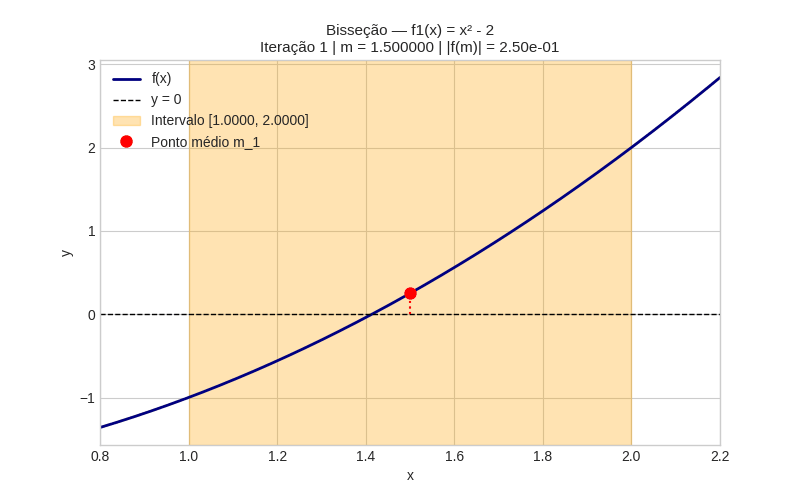

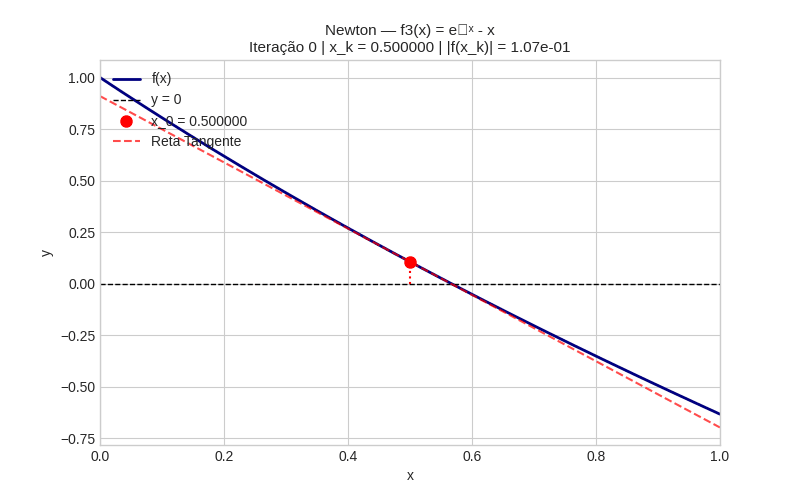

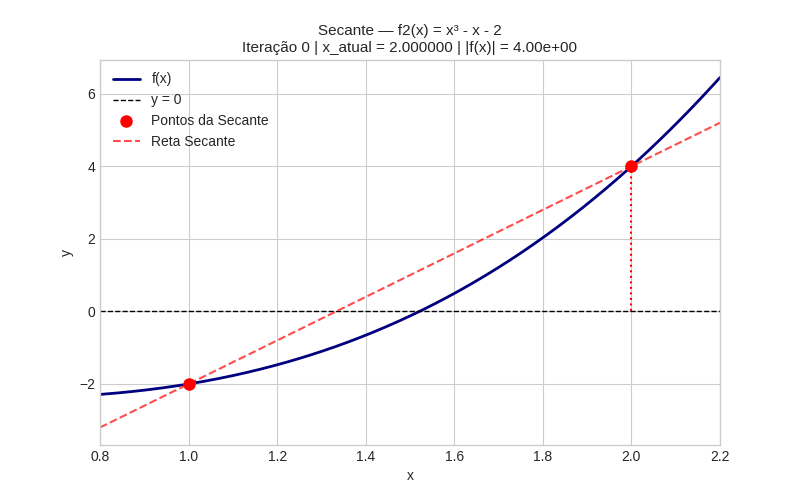

In [ ]:
import math
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np

# Configuração de estilo dos gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# ==========================================
# 1. ANIMAÇÃO: MÉTODO DA BISSEÇÃO
# ==========================================
def animar_bissecao(f, a0, b0, x_min, x_max, nome_funcao, nome_gif="bissecao.gif", max_iter=15, tol=1e-6):
    hist = []
    a, b = float(a0), float(b0)

    for k in range(1, max_iter + 1):
        m = a + (b - a) / 2.0
        fm = f(m)
        erro = (b - a) / 2.0
        hist.append({"k": k, "a": a, "b": b, "m": m, "fm": fm, "erro": erro})

        if abs(fm) < tol or erro < tol:
            break
        if f(a) * fm < 0:
            b = m
        else:
            a = m

    fig, ax = plt.subplots(figsize=(8, 5))
    x_vals = np.linspace(x_min, x_max, 400)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        dados = hist[frame]

        # Curva f(x) e eixo y=0
        ax.plot(x_vals, y_vals, label="f(x)", color="navy", lw=2)
        ax.axhline(0, color="black", linestyle="--", linewidth=1, label="y = 0")

        # Destaque do intervalo [a, b] na iteração atual
        ax.axvspan(dados["a"], dados["b"], color="orange", alpha=0.3, label=f"Intervalo [{dados['a']:.4f}, {dados['b']:.4f}]")

        # Ponto médio (aproximação atual)
        ax.plot(dados["m"], dados["fm"], "ro", markersize=8, label=f"Ponto médio m_{dados['k']}")
        ax.vlines(dados["m"], 0, dados["fm"], color="red", linestyle=":")

        ax.set_xlim(x_min, x_max)
        ax.set_title(f"Bisseção — {nome_funcao}\nIteração {dados['k']} | m = {dados['m']:.6f} | |f(m)| = {abs(dados['fm']):.2e}", fontsize=11)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend(loc="upper left")

    anim = animation.FuncAnimation(fig, update, frames=len(hist), interval=1000, repeat=False)
    anim.save(nome_gif, writer="pillow", fps=1)
    plt.close()
    print(f"Animação da Bisseção salva como '{nome_gif}'")

# ==========================================
# 2. ANIMAÇÃO: MÉTODO DE NEWTON
# ==========================================
def animar_newton(f, df, x0, x_min, x_max, nome_funcao, nome_gif="newton.gif", max_iter=15, tol=1e-6):
    hist = []
    x = float(x0)

    for k in range(max_iter):
        fx = f(x)
        dfx = df(x)
        hist.append({"k": k, "x": x, "fx": fx, "dfx": dfx})

        if abs(fx) < tol or abs(dfx) <= 1e-14:
            break

        x_novo = x - fx / dfx
        if abs(x_novo - x) < tol:
            hist.append({"k": k + 1, "x": x_novo, "fx": f(x_novo), "dfx": df(x_novo)})
            break
        x = x_novo

    fig, ax = plt.subplots(figsize=(8, 5))
    x_vals = np.linspace(x_min, x_max, 400)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        dados = hist[frame]

        # Curva f(x) e eixo y=0
        ax.plot(x_vals, y_vals, label="f(x)", color="navy", lw=2)
        ax.axhline(0, color="black", linestyle="--", linewidth=1, label="y = 0")

        # Ponto atual na curva
        ax.plot(dados["x"], dados["fx"], "ro", markersize=8, label=f"x_{dados['k']} = {dados['x']:.6f}")

        # Reta tangente à curva no ponto (x_k, f(x_k))
        if abs(dados["dfx"]) > 1e-14:
            tangente_x = np.linspace(x_min, x_max, 100)
            tangente_y = dados["fx"] + dados["dfx"] * (tangente_x - dados["x"])
            ax.plot(tangente_x, tangente_y, "r--", alpha=0.7, label="Reta Tangente")

        ax.vlines(dados["x"], 0, dados["fx"], color="red", linestyle=":")

        ax.set_xlim(x_min, x_max)
        ax.set_title(f"Newton — {nome_funcao}\nIteração {dados['k']} | x_k = {dados['x']:.6f} | |f(x_k)| = {abs(dados['fx']):.2e}", fontsize=11)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend(loc="upper left")

    anim = animation.FuncAnimation(fig, update, frames=len(hist), interval=1000, repeat=False)
    anim.save(nome_gif, writer="pillow", fps=1)
    plt.close()
    print(f"Animação de Newton salva como '{nome_gif}'")

# ==========================================
# 3. ANIMAÇÃO: MÉTODO DA SECANTE
# ==========================================
def animar_secante(f, x0, x1, x_min, x_max, nome_funcao, nome_gif="secante.gif", max_iter=15, tol=1e-6):
    hist = []
    x_ant = float(x0)
    x_at = float(x1)

    for k in range(max_iter):
        f_ant = f(x_ant)
        f_at = f(x_at)
        hist.append({"k": k, "x0": x_ant, "x1": x_at, "f0": f_ant, "f1": f_at})

        if abs(f_at) < tol:
            break

        denom = f_at - f_ant
        if abs(denom) <= 1e-14:
            break

        x_novo = x_at - f_at * (x_at - x_ant) / denom
        if abs(x_novo - x_at) < tol:
            hist.append({"k": k + 1, "x0": x_at, "x1": x_novo, "f0": f_at, "f1": f(x_novo)})
            break

        x_ant, x_at = x_at, x_novo

    fig, ax = plt.subplots(figsize=(8, 5))
    x_vals = np.linspace(x_min, x_max, 400)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        dados = hist[frame]

        # Curva f(x) e eixo y=0
        ax.plot(x_vals, y_vals, label="f(x)", color="navy", lw=2)
        ax.axhline(0, color="black", linestyle="--", linewidth=1, label="y = 0")

        # Pontos usados no passo atual
        ax.plot([dados["x0"], dados["x1"]], [dados["f0"], dados["f1"]], "ro", markersize=8, label="Pontos da Secante")

        # Reta secante passando pelos dois pontos
        m_sec = (dados["f1"] - dados["f0"]) / (dados["x1"] - dados["x0"])
        sec_x = np.linspace(x_min, x_max, 100)
        sec_y = dados["f1"] + m_sec * (sec_x - dados["x1"])
        ax.plot(sec_x, sec_y, "r--", alpha=0.7, label="Reta Secante")

        ax.vlines(dados["x1"], 0, dados["f1"], color="red", linestyle=":")

        ax.set_xlim(x_min, x_max)
        ax.set_title(f"Secante — {nome_funcao}\nIteração {dados['k']} | x_atual = {dados['x1']:.6f} | |f(x)| = {abs(dados['f1']):.2e}", fontsize=11)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend(loc="upper left")

    anim = animation.FuncAnimation(fig, update, frames=len(hist), interval=1000, repeat=False)
    anim.save(nome_gif, writer="pillow", fps=1)
    plt.close()
    print(f"Animação da Secante salva como '{nome_gif}'")

# ==========================================
# EXECUÇÃO E GERAÇÃO DOS ARQUIVOS GIF
# ==========================================
# 1. Bisseção para f1(x) = x^2 - 2
animar_bissecao(lambda x: x**2 - 2, a0=1.0, b0=2.0, x_min=0.8, x_max=2.2, nome_funcao="f1(x) = x² - 2", nome_gif="bissecao_f1.gif")

# 2. Newton para f3(x) = e^(-x) - x
animar_newton(lambda x: math.exp(-x) - x, lambda x: -math.exp(-x) - 1, x0=0.5, x_min=0.0, x_max=1.0, nome_funcao="f3(x) = e⁻ˣ - x", nome_gif="newton_f3.gif")

# 3. Secante para f2(x) = x^3 - x - 2
animar_secante(lambda x: x**3 - x - 2, x0=1.0, x1=2.0, x_min=0.8, x_max=2.2, nome_funcao="f2(x) = x³ - x - 2", nome_gif="secante_f2.gif")

from IPython.display import Image, display

# Exibir os três GIFs gerados
display(Image(filename="bissecao_f1.gif"))
display(Image(filename="newton_f3.gif"))
display(Image(filename="secante_f2.gif"))

In [ ]:
import ipywidgets as widgets
from IPython.display import HTML, Image, display
import pandas as pd

# 1. Dados da Tabela Comparativa de Resultados
dados_tabela = [
    # f1
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Bisseção",
        "Valores iniciais": "[1, 2]",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "1.03e-07",
        "Iterações/resultado": "20 (convergiu pelo erro do intervalo)",
    },
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = 1.5",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "8.88e-16",
        "Iterações/resultado": "3 (convergiu pelo resíduo)",
    },
    {
        "Função": "f1(x) = x² - 2",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (1, 2)",
        "Raiz aproximada": "1.41421356",
        "|f(x)| final": "4.44e-16",
        "Iterações/resultado": "4 (convergiu pelo resíduo)",
    },
    # f2
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Bisseção",
        "Valores iniciais": "[1, 2]",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "1.76e-06",
        "Iterações/resultado": "19 (convergiu pelo resíduo)",
    },
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = 1.5",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "1.78e-15",
        "Iterações/resultado": "3 (convergiu pelo resíduo)",
    },
    {
        "Função": "f2(x) = x³ - x - 2",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (1, 2)",
        "Raiz aproximada": "1.52137971",
        "|f(x)| final": "2.44e-10",
        "Iterações/resultado": "5 (convergiu pelo resíduo)",
    },
    # f3
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Bisseção",
        "Valores iniciais": "[0, 1]",
        "Raiz aproximada": "0.56714344",
        "|f(x)| final": "2.42e-07",
        "Iterações/resultado": "19 (convergiu pelo resíduo)",
    },
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Newton",
        "Valores iniciais": "x0 = 0.5",
        "Raiz aproximada": "0.56714329",
        "|f(x)| final": "0.00e+00",
        "Iterações/resultado": "3 (convergiu pelo resíduo)",
    },
    {
        "Função": "f3(x) = e^(-x) - x",
        "Método": "Secante",
        "Valores iniciais": "(x0, x1) = (0, 1)",
        "Raiz aproximada": "0.56714329",
        "|f(x)| final": "0.00e+00",
        "Iterações/resultado": "4 (convergiu pelo resíduo)",
    },
    # f4
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Bisseção",
        "Valores iniciais": "[-2, -1]",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "5.39e-07",
        "Iterações/resultado": "19 (convergiu pelo resíduo)",
    },
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Newton",
        "Valores iniciais": "x0 = -2.0",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "2.22e-16",
        "Iterações/resultado": "4 (convergiu pelo resíduo)",
    },
    {
        "Função": "f4(x) = x³ - 2x + 2",
        "Método": "Secante",
        "Valores iniciais": "(-2, -1)",
        "Raiz aproximada": "-1.76929235",
        "|f(x)| final": "6.92e-10",
        "Iterações/resultado": "5 (convergiu pelo resíduo)",
    },
]

df_res = pd.DataFrame(dados_tabela)

# 2. Componentes visuais do Dashboard
titulo = widgets.HTML(
    value="<h2 style='text-align: center; color: #1E3A8A; font-family: sans-serif;'>"
    "Dashboard de Métodos Numéricos (Resolução de Equações)</h2>"
)

# Aba 1: Tabela Completa
out_tabela = widgets.Output()
with out_tabela:
    display(
        HTML(
            "<h3 style='color: #2563EB;'>Tabela Comparativa de Resultados</h3>"
        )
    )
    display(df_res)

# Aba 2: Animação Bisseção
out_bissecao = widgets.Output()
with out_bissecao:
    display(
        HTML(
            "<h3>Método da Bisseção em f<sub>1</sub>(x) = x² - 2</h3>"
            "<p>Exibe o intervalo [a, b] e sua redução a cada passo.</p>"
        )
    )
    try:
        display(Image(filename="bissecao_f1.gif"))
    except Exception:
        print(
            "Ficheiro 'bissecao_f1.gif' não encontrado. Execute o código de geração primeiro."
        )

# Aba 3: Animação Newton
out_newton = widgets.Output()
with out_newton:
    display(
        HTML(
            "<h3>Método de Newton em f<sub>3</sub>(x) = e<sup>-x</sup> - x</h3>"
            "<p>Exibe as retas tangentes traçadas pela derivada a cada iteração.</p>"
        )
    )
    try:
        display(Image(filename="newton_f3.gif"))
    except Exception:
        print(
            "Ficheiro 'newton_f3.gif' não encontrado. Execute o código de geração primeiro."
        )

# Aba 4: Animação Secante
out_secante = widgets.Output()
with out_secante:
    display(
        HTML(
            "<h3>Método da Secante em f<sub>2</sub>(x) = x³ - x - 2</h3>"
            "<p>Exibe as retas secantes passando pelos dois pontos anteriores.</p>"
        )
    )
    try:
        display(Image(filename="secante_f2.gif"))
    except Exception:
        print(
            "Ficheiro 'secante_f2.gif' não encontrado. Execute o código de geração primeiro."
        )

# 3. Organização do Dashboard em Abas (Tabs)
dashboard = widgets.Tab()
dashboard.children = [out_tabela, out_bissecao, out_newton, out_secante]
dashboard.set_title(0, "📊 Tabela Comparativa")
dashboard.set_title(1, "🎬 Bisseção (GIF)")
dashboard.set_title(2, "🎬 Newton (GIF)")
dashboard.set_title(3, "🎬 Secante (GIF)")

# Exibir o Dashboard
display(widgets.VBox([titulo, dashboard]))